# L6 / E24 — Qwen2.5-3B-Instruct · P0 preprocessing (zero-shot)

**Controlled text-preprocessing experiment.** Uses E23’s fixed question-aware zero-shot prompt, Qwen model and scoring. Only the input text is changed from RAW to **P0**. The 14,639 redacted source rows remain in their original order. Original human labels are accessed only in Cell #9.


**Hypothesis:** Compared with E23's raw-text baseline, **P0** preprocessing may change how Qwen interprets airline tweets. This is exploratory: cleaning may remove useful contextual cues, and P2 may remove function words despite protecting negation.

**Controlled variables:** E23 prompt and Qwen2.5-3B-Instruct, greedy decoding, batch size, metrics, and label boundary are retained. Only preprocessing differs. Compare accuracy, Macro F1 and per-class recall with E23; no improvement is assumed.


In [1]:
# 1 — Minimal Colab dependencies; do not force-reinstall numerical libraries
%pip install -q transformers accelerate safetensors emoji num2words wordninja wordfreq symspellpy spacy gensim


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


**Run sequentially in Google Colab (T4 GPU recommended).** This notebook regenerates P0 text from the redacted source CSV with the repository's reusable `preprocessing.py` and `config.py`; it does not load earlier processed CSVs. The prompt is the same as E23. The original labelled CSV path is entered only in Cell #9.


In [2]:
# 2 — Input and output locations (no labelled CSV here)
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
INPUT_CSV = Path('/content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E24')
assert INPUT_CSV.is_file(), f'Missing redacted text CSV: {INPUT_CSV}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Unlabelled input:', INPUT_CSV)
print('Outputs:', OUTPUT_DIR)

Mounted at /content/drive
Unlabelled input: /content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv
Outputs: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E24


In [3]:
# 3 — Read text only; preserve original row positions
import numpy as np, pandas as pd, json, hashlib, platform, datetime
import importlib.metadata as im

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw = pd.read_csv(INPUT_CSV, usecols=['text'], dtype={'text':'string'})
assert raw['text'].notna().all(), 'Null source tweets'
assert len(raw) == 14639, f'Expected 14639 tweets, got {len(raw)}'
texts = raw['text'].astype(str).tolist()
source_row = np.arange(len(texts), dtype=np.int64)
source_sha = sha256_file(INPUT_CSV)
text_digest = hashlib.sha256(json.dumps(texts, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Tweets:', len(texts), '| SHA256:', source_sha)

Tweets: 14639 | SHA256: a41aeefcff9740c090153f608691d345c84f59084e40f03169c2f667df66578e


### E24 — P0 preprocessing ablation

Use **the exact E23 prompt**, not a newly tuned prompt. The only experimental treatment is applying the repository's frozen **P0_CONFIG** to each tweet. Source text, labels and row order remain unchanged for evaluation.


In [4]:
# 4 — Load public Qwen model locally (no API key)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
assert torch.cuda.is_available(), 'GPU required for this notebook. Colab: Runtime > Change runtime type > T4 GPU.'
MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'
PROMPT = (
    'Classify the overall sentiment expressed in this airline customer tweet toward the airline experience. '
    'Return exactly one lowercase label: negative, neutral, or positive. '
    'NEGATIVE: expresses dissatisfaction, frustration, criticism, disappointment, or a complaint, '
    'including implicit complaints. '
    'NEUTRAL: primarily states facts, asks for information, or gives an operational update without '
    'clearly expressing satisfaction or dissatisfaction. Do not infer negative sentiment solely '
    'because a delay, cancellation, or other undesirable event is mentioned. '
    'A question can still be negative if it clearly expresses frustration or criticism. '
    'POSITIVE: expresses praise, satisfaction, gratitude, appreciation, or happiness. '
    'Consider context and negation. Choose the overall expressed attitude, not merely the topic. '
    'A question mark or interrogative form is not by itself evidence of negative, neutral, or positive sentiment. '
    'Judge questions by their meaning, intent, and full context, not their punctuation. '
    'A genuine request for information with no expressed praise or dissatisfaction is neutral. '
    'A rhetorical or pointed question expressing criticism, frustration, or dissatisfaction is negative. '
    'A question genuinely expressing praise or appreciation is positive. '
    'Do not automatically mark questions about delays, cancellations, baggage, or bookings as negative, '
    'and do not automatically mark every question as neutral. '
    'Reply with only one lowercase label. Do not explain.'
)
MAX_NEW_TOKENS = 8
BATCH_SIZE = 8  # Reduce to 4 or 2 if CUDA out-of-memory occurs.
DTYPE = torch.float16

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE, device_map='auto', low_cpu_mem_usage=True
)
model.eval()
print('Loaded:', MODEL_ID, '| GPU:', torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-3B-Instruct | GPU: Tesla T4


In [5]:
# 5 — Fresh P0 preprocessing using the repository's reusable code
# Never read previously generated L1–L5 features or processed tweet files.
import subprocess, sys
REPO_DIR = Path('/content/l6_source_code')
REPO_URL = 'https://github.com/frankie-chew-nus/sentiment-clustering-ml.git'
if not (REPO_DIR / '.git').exists():
    assert not REPO_DIR.exists(), f'Unexpected directory: {REPO_DIR}'
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)
GIT_REVISION = subprocess.check_output(
    ['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
from preprocessing import preprocess_text
from config import P0_CONFIG

PREPROCESS_CONFIG = dict(P0_CONFIG)
PREPROCESS_PROFILE = 'P0'
processed_texts = [preprocess_text(t, PREPROCESS_CONFIG) for t in texts]
assert len(processed_texts) == len(texts)
assert all(isinstance(t, str) for t in processed_texts)
assert all(t.strip() for t in processed_texts), 'Empty processed text detected'
processed_digest = hashlib.sha256(
    json.dumps(processed_texts, ensure_ascii=False).encode('utf-8')
).hexdigest()
preprocess_config_digest = hashlib.sha256(
    json.dumps(PREPROCESS_CONFIG, sort_keys=True, default=str).encode('utf-8')
).hexdigest()
print('Preprocessing:', PREPROCESS_PROFILE, '| Git revision:', GIT_REVISION)
print('Rows:', len(processed_texts), '| Changed:', sum(a != b for a,b in zip(texts, processed_texts)))
print('Processed text SHA256:', processed_digest)
for i in range(3):
    print(f'Row {i} RAW:', texts[i][:150])
    print(f'Row {i} P0:', processed_texts[i][:150])


Preprocessing: P0 | Git revision: 892aeb4047ab947d445195a2ad5780d1b2efa89b
Rows: 14639 | Changed: 14639
Processed text SHA256: 5213697651c3682a00fa17cfa85036b32e1eb4a2047e3253aba25f92d03b869e
Row 0 RAW: @VirginAmerica What @dhepburn said.
Row 0 P0: airline What said.
Row 1 RAW: @VirginAmerica plus you've added commercials to the experience... tacky.
Row 1 P0: airline plus you've added commercials to the experience... tacky.
Row 2 RAW: @VirginAmerica I didn't today... Must mean I need to take another trip!
Row 2 P0: airline I didn't today... Must mean I need to take another trip!


In [6]:
# 6 — Run controls and resumable checkpoint
# Pilot: RUN_LIMIT=10. Full: RUN_LIMIT=None and CONFIRM_FULL_RUN=True.
# The pilot does not load human labels; review predictions in the checkpoint first.
RUN_LIMIT = None
CONFIRM_FULL_RUN = True
if RUN_LIMIT is None:
    assert CONFIRM_FULL_RUN, 'Set CONFIRM_FULL_RUN=True before processing all 14639 tweets.'
    target_n = len(texts)
else:
    assert isinstance(RUN_LIMIT, int) and 1 <= RUN_LIMIT <= len(texts)
    target_n = RUN_LIMIT
CHECKPOINT = OUTPUT_DIR / 'E24_qwen_prediction_checkpoint.csv'
CHECKPOINT_META = OUTPUT_DIR / 'E24_qwen_checkpoint_config.json'
run_identity = {
    'model_id':MODEL_ID,
    'prompt_sha256':hashlib.sha256(PROMPT.encode('utf-8')).hexdigest(),
    'source_sha256':source_sha,
    'text_sequence_sha256':text_digest,
    'processed_text_sequence_sha256': processed_digest,
    'preprocessing_profile': PREPROCESS_PROFILE,
    'preprocess_config_sha256': preprocess_config_digest,
    'git_revision': GIT_REVISION,
    'max_new_tokens':MAX_NEW_TOKENS,
    'decoding':'greedy',
    'transformers_version': im.version('transformers'),
}

if CHECKPOINT_META.exists():
    saved_identity = json.loads(
        CHECKPOINT_META.read_text(encoding="utf-8")
    )

    # Transformers version is recorded but not used as a
    # strict checkpoint compatibility requirement.
    compatibility_keys = set(run_identity) - {"transformers_version"}

    assert all(
        saved_identity.get(key) == run_identity.get(key)
        for key in compatibility_keys
    ), "Checkpoint configuration differs in a prediction-relevant field."

    print("Checkpoint configuration verified.")
    print("Original Transformers version:",
          saved_identity.get("transformers_version"))
    print("Current Transformers version:",
          run_identity.get("transformers_version"))
else:
    assert not CHECKPOINT.exists(), 'Checkpoint exists without metadata'
    CHECKPOINT_META.write_text(json.dumps(run_identity,indent=2),encoding='utf-8')
print('Target rows:',target_n,'| Batch size:',BATCH_SIZE)

Target rows: 14639 | Batch size: 8


In [7]:
# 7 — Classify in batches with deterministic decoding and checkpoints
import re, gc
VALID_LABELS = {'negative','neutral','positive'}

def tweet_hash(text):
    return hashlib.sha256(text.encode('utf-8')).hexdigest()

def classify_batch(tweet_batch):
    conversations = [
        [{'role':'system','content':PROMPT}, {'role':'user','content':str(tweet)}]
        for tweet in tweet_batch
    ]
    prompts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
               for m in conversations]
    inputs = tokenizer(prompts, return_tensors='pt', padding=True, truncation=True, max_length=512)
    inputs = {k:v.to(model.device) for k,v in inputs.items()}
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS,
                                 do_sample=False, pad_token_id=tokenizer.pad_token_id)
    prefix_len = inputs['input_ids'].shape[1]
    decoded = tokenizer.batch_decode(outputs[:,prefix_len:], skip_special_tokens=True)
    results = [s.strip().lower() for s in decoded]
    for value in results:
        if value not in VALID_LABELS:
            raise ValueError(f'Unexpected response {value!r}; stop and inspect, do not relabel silently.')
    return results

if CHECKPOINT.exists():
    progress = pd.read_csv(CHECKPOINT)
    assert {'source_row','prediction','text_sha256'}.issubset(progress.columns)
    assert progress['source_row'].is_unique
else:
    progress = pd.DataFrame(columns=['source_row','prediction','text_sha256'])
cache = {int(r.source_row):(str(r.prediction),str(r.text_sha256)) for r in progress.itertuples()}
assert all(0 <= i < len(texts) and pred in VALID_LABELS and digest == tweet_hash(processed_texts[i])
           for i,(pred,digest) in cache.items()), 'Invalid checkpoint content'

def save_checkpoint():
    pd.DataFrame([{'source_row':i,'prediction':v[0],'text_sha256':v[1]}
                  for i,v in sorted(cache.items())]).to_csv(CHECKPOINT,index=False)

missing = [i for i in range(target_n) if i not in cache]
for start in range(0,len(missing),BATCH_SIZE):
    batch_ids = missing[start:start+BATCH_SIZE]
    preds = classify_batch([processed_texts[i] for i in batch_ids])
    for i,pred in zip(batch_ids,preds):
        cache[i] = (pred,tweet_hash(processed_texts[i]))
    save_checkpoint()  # Persist every batch for Colab interruptions.
    if (start//BATCH_SIZE)%25 == 0 or start+BATCH_SIZE >= len(missing):
        print(f'Completed {len(cache)}/{target_n} target rows (checkpoint saved)')
print('Predictions in checkpoint:',len(cache))

Completed 8/14639 target rows (checkpoint saved)
Completed 208/14639 target rows (checkpoint saved)
Completed 408/14639 target rows (checkpoint saved)
Completed 608/14639 target rows (checkpoint saved)
Completed 808/14639 target rows (checkpoint saved)
Completed 1008/14639 target rows (checkpoint saved)
Completed 1208/14639 target rows (checkpoint saved)
Completed 1408/14639 target rows (checkpoint saved)
Completed 1608/14639 target rows (checkpoint saved)
Completed 1808/14639 target rows (checkpoint saved)
Completed 2008/14639 target rows (checkpoint saved)
Completed 2208/14639 target rows (checkpoint saved)
Completed 2408/14639 target rows (checkpoint saved)
Completed 2608/14639 target rows (checkpoint saved)
Completed 2808/14639 target rows (checkpoint saved)
Completed 3008/14639 target rows (checkpoint saved)
Completed 3208/14639 target rows (checkpoint saved)
Completed 3408/14639 target rows (checkpoint saved)
Completed 3608/14639 target rows (checkpoint saved)
Completed 3808/1463

In [8]:
# 8 — Freeze predictions BEFORE loading human sentiment labels
assert target_n == len(texts), 'Pilot only. Set RUN_LIMIT=None, CONFIRM_FULL_RUN=True and rerun Cells #6–#8.'
assert set(cache) == set(range(len(texts))), 'Missing predictions'
predictions = np.array([cache[i][0] for i in range(len(texts))])
assert set(predictions).issubset(VALID_LABELS)
assign_path = OUTPUT_DIR / 'E24_zero_shot_predictions.csv'
pd.DataFrame({'source_row':source_row,'predicted_sentiment':predictions}).to_csv(assign_path,index=False)
manifest = {'experiment':'E24','stage':'foundation_model_zero_shot',
            'task':'direct_sentiment_classification','model_id':MODEL_ID,
            'prompt':PROMPT,'rows':len(texts),'source_sha256':source_sha,
            'text_sequence_sha256':text_digest,
            'processed_text_sequence_sha256': processed_digest,
            'preprocessing_profile': PREPROCESS_PROFILE,
            'preprocess_config': PREPROCESS_CONFIG,
            'preprocess_config_sha256': preprocess_config_digest,
            'git_revision': GIT_REVISION,
            'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
            'predictions_sha256':sha256_file(assign_path), 'silhouette':None,
            'no_training_examples':True, 'max_new_tokens':MAX_NEW_TOKENS,
            'decoding':'greedy','batch_size':BATCH_SIZE,
            'versions':{'transformers':im.version('transformers'),
                        'torch':im.version('torch'),'pandas':im.version('pandas')}}
(OUTPUT_DIR/'E24_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Predictions frozen before labels:',assign_path)

Predictions frozen before labels: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E24/E24_zero_shot_predictions.csv


In [9]:
# 9 — ONLY labelled-data access cell: manually enter your labelled CSV path
LABEL_CSV = Path('ENTER_LABELLED_CSV_PATH')
assert LABEL_CSV.is_file(), f'Labelled CSV missing: {LABEL_CSV}'
assert LABEL_CSV.resolve() != INPUT_CSV.resolve()
saved = pd.read_csv(assign_path)
assert np.array_equal(saved['source_row'].to_numpy(),source_row)
assert sha256_file(INPUT_CSV) == source_sha
label_texts = pd.read_csv(LABEL_CSV,usecols=['text'],dtype={'text':'string'})['text']
assert label_texts.notna().all()
assert label_texts.astype(str).tolist() == texts, 'Tweet text/order mismatch'
labels = pd.read_csv(LABEL_CSV,usecols=['airline_sentiment'],dtype={'airline_sentiment':'string'})['airline_sentiment']
assert len(labels)==len(texts) and labels.notna().all()
assert set(labels.unique()) == VALID_LABELS
y_true = labels.astype(str).to_numpy()
y_pred = saved['predicted_sentiment'].astype(str).to_numpy()
print('Aligned original human labels; predictions already frozen.')

Aligned original human labels; predictions already frozen.


In [10]:
# 10 — Direct classification metrics: no Hungarian cluster mapping
from sklearn.metrics import (adjusted_rand_score,normalized_mutual_info_score,
                             accuracy_score,precision_recall_fscore_support)
CLASSES=['negative','neutral','positive']
CONFUSION=pd.crosstab(pd.Series(y_true,name='true_sentiment'),
                      pd.Series(y_pred,name='predicted_sentiment')).reindex(
                      index=CLASSES,columns=CLASSES,fill_value=0)
precision,recall,f1,support=precision_recall_fscore_support(
    y_true,y_pred,labels=CLASSES,zero_division=0)
per_class=pd.DataFrame({'sentiment':CLASSES,'precision':precision,'recall':recall,
                        'f1':f1,'support':support})
composition=CONFUSION.div(CONFUSION.sum(axis=0).replace(0,np.nan),axis=1).T.fillna(0)*100
# Descriptive purity of predicted groups; not a primary classifier metric.
purity=float(CONFUSION.max(axis=0).sum()/len(y_true))
metrics={'experiment':'E24','n':len(y_true),'ari':float(adjusted_rand_score(y_true,y_pred)),
         'nmi':float(normalized_mutual_info_score(y_true,y_pred)),
         'purity':purity,'accuracy':float(accuracy_score(y_true,y_pred)),
         'macro_f1':float(np.mean(f1)),'silhouette_2000':None,
         'majority_class_baseline':float(max(np.unique(y_true,return_counts=True)[1])/len(y_true))}
print(metrics)
display(CONFUSION,per_class)

{'experiment': 'E24', 'n': 14639, 'ari': 0.5779598914321392, 'nmi': 0.4189314945719557, 'purity': 0.8219140651683858, 'accuracy': 0.8219140651683858, 'macro_f1': 0.7597708213624291, 'silhouette_2000': None, 'majority_class_baseline': 0.6269553931279459}


predicted_sentiment,negative,neutral,positive
true_sentiment,,,
negative,8378,552,248
neutral,925,1685,489
positive,131,262,1969


,sentiment,precision,recall,f1,support
0,negative,0.888064,0.912835,0.900279,9178
1,neutral,0.674270,0.543724,0.602001,3099
2,positive,0.727642,0.833616,0.777032,2362


In [11]:
# 11 — Silhouette is not applicable to direct label predictions
print('Silhouette: N/A — no clustering vectors or discovered cluster geometry.')

Silhouette: N/A — no clustering vectors or discovered cluster geometry.


In [12]:
# 12 — Save numerical evidence; no GitHub writes
CONFUSION.to_csv(OUTPUT_DIR/'E24_confusion_matrix.csv')
composition.to_csv(OUTPUT_DIR/'E24_predicted_group_composition.csv')
per_class.to_csv(OUTPUT_DIR/'E24_per_class_metrics.csv',index=False)
(OUTPUT_DIR/'E24_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Saved:',OUTPUT_DIR)

Saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E24


## Interpretation and comparison with E23 (RAW)

**E24 changes only text preprocessing to P0.** The Qwen model, fixed E23 question-aware prompt, generation settings, labelled-data boundary and metrics remain unchanged. Source rows and labels are aligned against the original raw tweet text, not the processed text.

**Reference E23 (RAW):** direct accuracy approximately 0.8230, Macro F1 0.7603, neutral recall 0.5292. These are prior results, not recalculated here.

**Primary checks:** compare Macro F1, accuracy, neutral recall, negative/positive F1 and the confusion matrix against E23. Any improvement is exploratory because previous results informed this design. Silhouette remains N/A for direct classification.

**Caution:** P0 may remove useful punctuation, emoji or lexical nuance; do not assume more cleaning is better for pretrained Transformers.


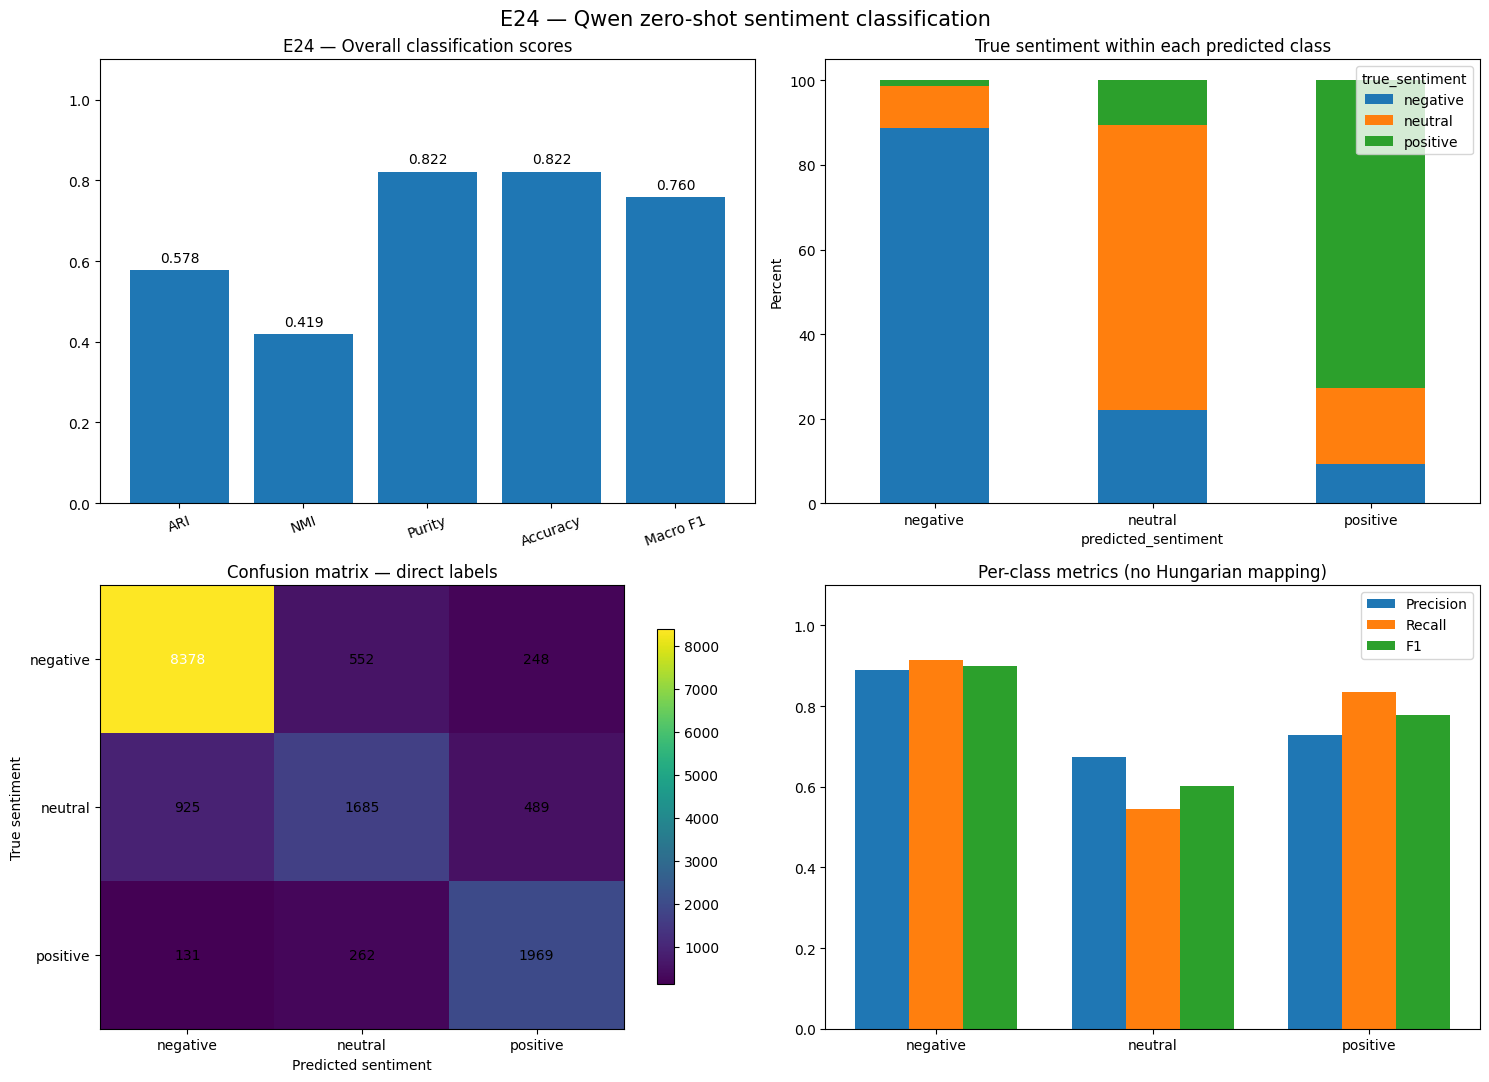

Saved: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E24/figures/E24_evaluation.png


In [13]:
# 13 — Visualization: direct zero-shot classification (no cluster mapping)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(15,11))
keys=['ARI','NMI','Purity','Accuracy','Macro F1']
vals=[metrics['ari'],metrics['nmi'],metrics['purity'],metrics['accuracy'],metrics['macro_f1']]
axes[0,0].bar(keys,vals); axes[0,0].set_ylim(0,1.1)
axes[0,0].set_title('E24 — Overall classification scores')
axes[0,0].tick_params(axis='x',rotation=20)
for i,v in enumerate(vals): axes[0,0].text(i,v+0.02,f'{v:.3f}',ha='center')
composition.plot(kind='bar',stacked=True,ax=axes[0,1])
axes[0,1].set_title('True sentiment within each predicted class')
axes[0,1].set_ylabel('Percent');axes[0,1].tick_params(axis='x',rotation=0)
mat=CONFUSION.to_numpy()
im=axes[1,0].imshow(mat,aspect='auto',cmap='viridis')
axes[1,0].set_xticks(range(3),CLASSES);axes[1,0].set_yticks(range(3),CLASSES)
axes[1,0].set_xlabel('Predicted sentiment');axes[1,0].set_ylabel('True sentiment')
axes[1,0].set_title('Confusion matrix — direct labels')
for i in range(3):
    for j in range(3): axes[1,0].text(j,i,str(mat[i,j]),ha='center',va='center',color='white' if mat[i,j]>mat.max()/2 else 'black')
fig.colorbar(im,ax=axes[1,0],shrink=.8)
x=np.arange(3);w=.25
axes[1,1].bar(x-w,precision,w,label='Precision');axes[1,1].bar(x,recall,w,label='Recall');axes[1,1].bar(x+w,f1,w,label='F1')
axes[1,1].set_xticks(x,CLASSES);axes[1,1].set_ylim(0,1.1);axes[1,1].legend()
axes[1,1].set_title('Per-class metrics (no Hungarian mapping)')
fig.suptitle('E24 — Qwen zero-shot sentiment classification',fontsize=15)
plt.tight_layout()
fig_dir=OUTPUT_DIR/'figures';fig_dir.mkdir(exist_ok=True,parents=True)
fig.savefig(fig_dir/'E24_evaluation.png',dpi=200,bbox_inches='tight')
plt.show()
print('Saved:',fig_dir/'E24_evaluation.png')